
# Child Health & Environmental Risk Factors

### Data Analysis — Group Project

**University:** Széchenyi István University  
**Programme:** MSc Computer Science Engineering  
**Course:** Data Analysis

---

## 1. Project Introduction

Child health is influenced by many environmental, economic,
and social conditions. In this project, we explore how
air pollution and access to drinking water are associated
with under-five mortality across countries.

We combine publicly available data from three sources:

- **UNICEF:** Under-five mortality rates.
- **WHO:** Annual PM2.5 air pollution concentrations.
- **WHO/UNICEF JMP:** Drinking water service coverage.

The study covers **2010–2023**.

### Research Questions

1. Is air pollution associated with under-five mortality?
2. Is access to basic drinking water associated with
   lower child mortality?
3. Do these relationships remain similar when we account
   for country and year differences?

### Project Workflow

1. Data collection and cleaning
2. Data integration and validation
3. Exploratory data analysis
4. Correlation and statistical modelling
5. Robustness checks
6. Interactive Streamlit dashboard

### Methodological Note

This is an observational study. The results describe
statistical associations and do not establish causation.



## 2. Data Sources and Preparation

### 2.1 Data Sources

This project uses three publicly available datasets:

| Source | Data | Main Variable |
|---|---|---|
| UNICEF | Under-five mortality estimates | Under5_Mortality_Rate |
| WHO | Annual air pollution estimates | PM25 |
| WHO/UNICEF JMP | Drinking water coverage | Water_AtLeastBasic_Pct |

We selected these sources because they provide
country-level data that can be compared over time.

### 2.2 Data Preparation

Before the analysis, we:

1. Loaded the original Excel and CSV files.
2. Selected the required indicators.
3. Standardized country codes and years.
4. Combined the datasets using ISO3 and Year.
5. Checked missing values, duplicates, and invalid values.

### 2.3 Final Datasets

We prepared three datasets:

- **Master dataset:** 2,786 records from 199 countries.
- **Main analysis:** 2,713 records from 198 countries.
- **Secondary analysis:** 1,932 records from 139 countries.

The analysis covers **2010–2023**.

Missing drinking water values were not replaced
with zero. The original datasets were preserved.


In [1]:

import pandas as pd

file_path = "data/raw/Under-five_Mortality_Rates_2025-1.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="U5MR Country estimates",
    header=14
)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head(6))


Dataset loaded successfully!
Rows: 600
Columns: 82


,ISO.Code,Country.Name,SDG.Region,SDG.Subregion,UNICEF.Region,UNICEF.Programme.Region,Uncertainty.Bounds*,1950.5,1951.5,1952.5,...,2015.5,2016.5,2017.5,2018.5,2019.5,2020.5,2021.5,2022.5,2023.5,2024.5
0,AFG,Afghanistan,Central and Southern Asia,Southern Asia,South Asia,South Asia,Lower,NaN,NaN,NaN,...,63.729247,60.719911,57.728614,54.788317,51.927748,49.253441,46.749959,44.274556,42.017226,39.678880
1,AFG,Afghanistan,Central and Southern Asia,Southern Asia,South Asia,South Asia,Median,NaN,NaN,NaN,...,71.898430,69.371884,67.070567,64.823201,62.715734,60.692321,58.711673,56.770403,54.865098,53.032021
2,AFG,Afghanistan,Central and Southern Asia,Southern Asia,South Asia,South Asia,Upper,NaN,NaN,NaN,...,80.745189,78.757848,77.210286,75.841995,74.655724,73.793078,73.233005,72.482263,71.923851,71.364261
3,AGO,Angola,Sub-Saharan Africa,NaN,Eastern and Southern Africa,Eastern and Southern Africa,Lower,NaN,NaN,NaN,...,49.934774,48.259035,46.761888,45.300755,43.607005,41.536461,39.329341,37.254858,35.264147,33.345865
4,AGO,Angola,Sub-Saharan Africa,NaN,Eastern and Southern Africa,Eastern and Southern Africa,Median,NaN,NaN,NaN,...,61.760603,59.643040,57.899381,56.490285,55.348074,54.216138,53.177715,51.863987,50.513436,48.999666
5,AGO,Angola,Sub-Saharan Africa,NaN,Eastern and Southern Africa,Eastern and Southern Africa,Upper,NaN,NaN,NaN,...,76.168573,73.354658,71.595717,70.420043,70.229310,70.773781,71.992581,73.295192,74.594233,75.820292


In [2]:

# Keep only median mortality estimates
median_df = df[
    df["Uncertainty.Bounds*"] == "Median"
].copy()

# Check the filtered dataset
print("Countries:", len(median_df))
print("Columns:", median_df.shape[1])

# Preview country information
display(
    median_df[
        ["ISO.Code", "Country.Name", "Uncertainty.Bounds*"]
    ].head(10)
)


Countries: 200
Columns: 82


,ISO.Code,Country.Name,Uncertainty.Bounds*
1,AFG,Afghanistan,Median
4,AGO,Angola,Median
7,AIA,Anguilla,Median
10,ALB,Albania,Median
13,AND,Andorra,Median
16,ARE,United Arab Emirates,Median
19,ARG,Argentina,Median
22,ARM,Armenia,Median
25,ATG,Antigua and Barbuda,Median
28,AUS,Australia,Median


In [3]:

# Identify the columns containing years
year_columns = [
    col for col in median_df.columns
    if str(col).split(".")[0].isdigit()
    and 1950 <= int(str(col).split(".")[0]) <= 2024
]

# Convert wide data into long format
mortality_long = median_df.melt(
    id_vars=["ISO.Code", "Country.Name"],
    value_vars=year_columns,
    var_name="Year",
    value_name="Under5_Mortality_Rate"
)

# Convert years such as 2024.5 into 2024
mortality_long["Year"] = (
    mortality_long["Year"].astype(float).astype(int)
)

# Rename columns
mortality_long = mortality_long.rename(columns={
    "ISO.Code": "ISO3",
    "Country.Name": "Country"
})

# Check the result
print("Years found:", len(year_columns))
print("Total records:", len(mortality_long))
print("Unique countries:", mortality_long["ISO3"].nunique())
print("Year range:", mortality_long["Year"].min(),
      "-", mortality_long["Year"].max())

display(mortality_long.head(10))


Years found: 75
Total records: 15000
Unique countries: 200
Year range: 1950 - 2024


,ISO3,Country,Year,Under5_Mortality_Rate
0,AFG,Afghanistan,1950,NaN
1,AGO,Angola,1950,NaN
2,AIA,Anguilla,1950,NaN
3,ALB,Albania,1950,NaN
4,AND,Andorra,1950,NaN
5,ARE,United Arab Emirates,1950,NaN
6,ARG,Argentina,1950,NaN
7,ARM,Armenia,1950,NaN
8,ATG,Antigua and Barbuda,1950,118.807324
9,AUS,Australia,1950,31.583086


In [4]:

# STEP 7: Data Quality Check

# 1. Missing values
print("Total records:", len(mortality_long))
print("Missing values:",
      mortality_long["Under5_Mortality_Rate"].isna().sum())

# 2. Duplicate country-year records
duplicates = mortality_long.duplicated(
    subset=["ISO3", "Year"]
).sum()

print("Duplicate Country-Year records:", duplicates)

# 3. Missing values per year
missing_by_year = mortality_long.groupby("Year")[
    "Under5_Mortality_Rate"
].apply(lambda x: x.isna().sum())

print("\nMissing values in early years:")
display(missing_by_year.head(10))

# 4. Check more recent years
print("\nMissing values from 1990 to 2024:")
display(missing_by_year.loc[1990:2024])

# 5. Check invalid mortality values
rates = pd.to_numeric(
    mortality_long["Under5_Mortality_Rate"],
    errors="coerce"
)

print("Negative mortality rates:", (rates < 0).sum())


Total records: 15000
Missing values: 1904
Duplicate Country-Year records: 0

Missing values in early years:


Year
1950    135
1951    127
1952    119
1953    111
1954    103
1955     95
1956     85
1957     82
1958     74
1959     69
Name: Under5_Mortality_Rate, dtype: int64


Missing values from 1990 to 2024:


Year
1990    0
1991    0
1992    0
1993    0
1994    0
1995    0
1996    0
1997    0
1998    0
1999    0
2000    0
2001    0
2002    0
2003    0
2004    0
2005    0
2006    0
2007    0
2008    0
2009    0
2010    0
2011    0
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
Name: Under5_Mortality_Rate, dtype: int64

Negative mortality rates: 0


In [5]:

from pathlib import Path

# Create processed data folder
processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Prepare the final structured table
unicef_clean = mortality_long.copy()

# Ensure correct data types
unicef_clean["Year"] = unicef_clean["Year"].astype(int)

unicef_clean["Under5_Mortality_Rate"] = pd.to_numeric(
    unicef_clean["Under5_Mortality_Rate"],
    errors="coerce"
)

# Sort by country and year
unicef_clean = unicef_clean.sort_values(
    ["ISO3", "Year"]
).reset_index(drop=True)

# Save without changing missing values
output_path = processed_dir / "unicef_under5_mortality.csv"

unicef_clean.to_csv(output_path, index=False)

print("UNICEF dataset saved successfully!")
print("File:", output_path)
print("Rows:", len(unicef_clean))
print("Missing values:",
      unicef_clean["Under5_Mortality_Rate"].isna().sum())

display(unicef_clean.head())


UNICEF dataset saved successfully!
File: data\processed\unicef_under5_mortality.csv
Rows: 15000
Missing values: 1904


,ISO3,Country,Year,Under5_Mortality_Rate
0,AFG,Afghanistan,1950,NaN
1,AFG,Afghanistan,1951,NaN
2,AFG,Afghanistan,1952,NaN
3,AFG,Afghanistan,1953,NaN
4,AFG,Afghanistan,1954,NaN


In [6]:

# STEP 10: Prepare WHO PM2.5 data

import pandas as pd

# Load original WHO dataset
who_raw = pd.read_csv("data/raw/who_pm25.csv")

# Keep country-level total PM2.5 measurements
who_pm25 = who_raw[
    (who_raw["Dim1"] == "Total") &
    (who_raw["Location type"] == "Country")
].copy()

# Select useful columns
who_pm25 = who_pm25[
    [
        "SpatialDimValueCode",
        "Location",
        "Period",
        "FactValueNumeric"
    ]
]

# Rename columns to match UNICEF structure
who_pm25 = who_pm25.rename(columns={
    "SpatialDimValueCode": "ISO3",
    "Location": "Country",
    "Period": "Year",
    "FactValueNumeric": "PM25"
})

# Convert to numeric values
who_pm25["Year"] = who_pm25["Year"].astype(int)
who_pm25["PM25"] = pd.to_numeric(
    who_pm25["PM25"],
    errors="coerce"
)

# Sort the dataset
who_pm25 = who_pm25.sort_values(
    ["ISO3", "Year"]
).reset_index(drop=True)

# Verify results
print("WHO dataset prepared successfully!")
print("Total records:", len(who_pm25))
print("Countries:", who_pm25["ISO3"].nunique())
print("Years:", who_pm25["Year"].min(),
      "-", who_pm25["Year"].max())

print("Missing PM2.5 values:",
      who_pm25["PM25"].isna().sum())

print("Duplicate Country-Year records:",
      who_pm25.duplicated(["ISO3", "Year"]).sum())

display(who_pm25.head(10))


WHO dataset prepared successfully!
Total records: 3178
Countries: 227
Years: 2010 - 2023
Missing PM2.5 values: 0
Duplicate Country-Year records: 0


,ISO3,Country,Year,PM25
0,ABW,Aruba,2010,18.46
1,ABW,Aruba,2011,16.76
2,ABW,Aruba,2012,18.00
3,ABW,Aruba,2013,17.45
4,ABW,Aruba,2014,17.75
5,ABW,Aruba,2015,20.04
6,ABW,Aruba,2016,17.17
7,ABW,Aruba,2017,17.19
8,ABW,Aruba,2018,15.72
9,ABW,Aruba,2019,15.49


In [7]:

# STEP 11: Save WHO data and check overlap with UNICEF

from pathlib import Path

# 1. Save processed WHO data
output_path = Path("data/processed/who_pm25.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

who_pm25.to_csv(output_path, index=False)

print("WHO dataset saved successfully!")
print("File:", output_path)

# 2. Select the WHO time period from UNICEF
unicef_period = unicef_clean[
    unicef_clean["Year"].between(2010, 2023)
].copy()

# 3. Match country-year records
matched_data = unicef_period.merge(
    who_pm25[["ISO3", "Year", "PM25"]],
    on=["ISO3", "Year"],
    how="inner",
    validate="one_to_one"
)

# 4. Check overlap
print("\n--- DATASET MATCHING ---")
print("UNICEF countries:", unicef_period["ISO3"].nunique())
print("WHO countries:", who_pm25["ISO3"].nunique())
print("Matched countries:", matched_data["ISO3"].nunique())
print("Matched records:", len(matched_data))

print("Years:",
      matched_data["Year"].min(),
      "-",
      matched_data["Year"].max())

print("Missing mortality values:",
      matched_data["Under5_Mortality_Rate"].isna().sum())

print("Missing PM2.5 values:",
      matched_data["PM25"].isna().sum())

# 5. Preview matched records
display(
    matched_data[
        ["ISO3", "Country", "Year",
         "Under5_Mortality_Rate", "PM25"]
    ].head(10)
)


WHO dataset saved successfully!
File: data\processed\who_pm25.csv

--- DATASET MATCHING ---
UNICEF countries: 200
WHO countries: 227
Matched countries: 199
Matched records: 2786
Years: 2010 - 2023
Missing mortality values: 0
Missing PM2.5 values: 0


,ISO3,Country,Year,Under5_Mortality_Rate,PM25
0,AFG,Afghanistan,2010,87.956715,76.08
1,AFG,Afghanistan,2011,84.293223,69.96
2,AFG,Afghanistan,2012,80.814509,69.07
3,AFG,Afghanistan,2013,77.597499,73.84
4,AFG,Afghanistan,2014,74.614073,71.20
5,AFG,Afghanistan,2015,71.898430,71.53
6,AFG,Afghanistan,2016,69.371884,75.13
7,AFG,Afghanistan,2017,67.070567,72.07
8,AFG,Afghanistan,2018,64.823201,71.07
9,AFG,Afghanistan,2019,62.715734,60.08


In [8]:

# STEP 13: Explore JMP drinking water dataset

import pandas as pd

jmp_raw = pd.read_csv(
    "data/raw/jmp_drinking_water.csv"
)

print("Dataset loaded successfully!")
print("Total records:", len(jmp_raw))
print("Countries:", jmp_raw["country"].nunique())
print("Years:", jmp_raw["year"].min(),
      "-", jmp_raw["year"].max())

print("\nWater service levels:")
display(
    jmp_raw["service_level"]
    .value_counts()
    .rename_axis("Service Level")
    .reset_index(name="Records")
)

print("\nFirst records:")
display(jmp_raw.head())


Dataset loaded successfully!
Total records: 34736
Countries: 232
Years: 2010 - 2023

Water service levels:


,Service Level,Records
0,Insufficient data,3248
1,Improved,3157
2,Limited service,3157
3,Unimproved,3157
4,On premises,3115
5,Surface water,3061
6,Non-piped improved,3047
7,Piped improved,3047
8,Basic service,2268
9,Free from contamination,2268



First records:


,country,year,residence_type,service_type,service_level,value,population
0,ABW,2010,total,Drinking water,At least basic,96.488736,96598.732989
1,ABW,2010,total,Drinking water,Improved,96.488736,96598.732989
2,ABW,2010,total,Drinking water,Non-piped improved,3.511264,3515.267011
3,ABW,2010,total,Drinking water,On premises,94.733104,94841.099483
4,ABW,2010,total,Drinking water,Insufficient data,0.000000,0.000000


In [9]:

# STEP 14: Prepare drinking water indicators

import pandas as pd

# Make sure values are numeric
jmp_raw["value"] = pd.to_numeric(
    jmp_raw["value"], errors="coerce"
)

# Convert service levels into separate columns
water_wide = jmp_raw.pivot(
    index=["country", "year"],
    columns="service_level",
    values="value"
).reset_index()

# At least basic:
# Use the original value when available,
# otherwise calculate Basic + Safely managed
water_wide["Water_AtLeastBasic_Pct"] = (
    water_wide["At least basic"].combine_first(
        water_wide["Basic service"] +
        water_wide["Safely managed service"]
    )
)

# Keep safely managed as a separate indicator
water_wide["Water_SafelyManaged_Pct"] = (
    water_wide["Safely managed service"]
)

# Rename columns
water = water_wide.rename(columns={
    "country": "ISO3",
    "year": "Year"
})

# Select the columns needed for our project
water = water[
    [
        "ISO3",
        "Year",
        "Water_AtLeastBasic_Pct",
        "Water_SafelyManaged_Pct"
    ]
].copy()

water["Year"] = water["Year"].astype(int)

# Remove rows with no usable basic-water estimate
# Do NOT replace missing values with zero
water = water.dropna(
    subset=["Water_AtLeastBasic_Pct"]
).copy()

# Round small numerical precision differences
water["Water_AtLeastBasic_Pct"] = (
    water["Water_AtLeastBasic_Pct"].round(6)
)

# Check results
print("Water dataset prepared successfully!")
print("Total records:", len(water))
print("Countries:", water["ISO3"].nunique())

print("Years:",
      water["Year"].min(),
      "-",
      water["Year"].max())

print("Missing At least basic:",
      water["Water_AtLeastBasic_Pct"].isna().sum())

print("Missing Safely managed:",
      water["Water_SafelyManaged_Pct"].isna().sum())

print("Duplicate Country-Year:",
      water.duplicated(["ISO3", "Year"]).sum())

display(water.head(10))


Water dataset prepared successfully!
Total records: 3157
Countries: 231
Years: 2010 - 2023
Missing At least basic: 0
Missing Safely managed: 889
Duplicate Country-Year: 0


service_level,ISO3,Year,Water_AtLeastBasic_Pct,Water_SafelyManaged_Pct
0,ABW,2010,96.488736,NaN
1,ABW,2011,96.614256,NaN
2,ABW,2012,96.739776,NaN
3,ABW,2013,96.739776,NaN
4,ABW,2014,96.739776,NaN
5,ABW,2015,96.739776,NaN
6,ABW,2016,96.739776,NaN
14,AFG,2010,49.133795,19.224722
15,AFG,2011,51.389671,20.059192
16,AFG,2012,53.655809,20.893080



### 2.3.1 Data Provenance and Indicator Definitions

We used publicly available country-level data from
UNICEF, WHO, and the WHO/UNICEF Joint Monitoring
Programme (JMP).

#### UNICEF — Under-Five Mortality

**Local file:** `Under-five_Mortality_Rates_2025-1.xlsx`

**Worksheet:** `U5MR Country estimates`

**Indicator:** Under-five mortality rate, expressed
per 1,000 live births.

We selected the median estimates and reshaped the
country-level data into a country-year format.

Official reference:
https://data.unicef.org/resources/dataset/under-five-mortality-data/

#### WHO — PM2.5 Air Pollution

**Local file:** `who_pm25.csv`

**Indicator:** Annual mean PM2.5 concentration,
measured in micrograms per cubic metre (µg/m³).

We selected country-level observations where
`Dim1 = Total` and `Location type = Country`.

Official indicator documentation:
https://www.who.int/data/gho/data/indicators/indicator-details/GHO/concentrations-of-fine-particulate-matter-%28pm2-5%29

#### WHO/UNICEF JMP — Drinking Water

**Local file:** `jmp_drinking_water.csv`

**Indicators:**

- At least basic drinking water coverage (%).
- Safely managed drinking water coverage (%).

At least basic services include basic and safely
managed drinking water services.

When an explicit "At least basic" value was
unavailable, we calculated it by adding the
Basic service and Safely managed service values.

Official data documentation:
https://washdata.org/data/api

#### Data Version and Reproducibility

The analysis uses the original files stored in
`data/raw/`, rather than automatically replacing
them with newer online releases.

The source reference pages may contain updated
estimates that differ from the local data extracts.

The project preserves the original files and
provides the processing code needed to rebuild
the analysis datasets.

The exact retrieval dates and export versions of
the WHO and JMP files are not established by the
notebook alone.



### 2.4 Data Integration and Quality Control

#### Data Integration

After preparing the three datasets, we combined them
using two common fields:

- **ISO3:** Three-letter country code.
- **Year:** Observation year.

We first matched UNICEF mortality data with WHO
air pollution data. Then, we added drinking water
indicators from WHO/UNICEF JMP.

The resulting master dataset contains 2,786
country-year records from 199 countries.

#### Data Quality Checks

We checked the merged data for:

- Duplicate country-year records.
- Missing values.
- Negative mortality or PM2.5 values.
- Drinking water percentages outside 0–100%.
- Inconsistencies between water indicators.

No duplicates, invalid values, or inconsistent
water percentages were found.

However, some drinking water observations were
missing. We kept these values as missing instead
of replacing them with zero.

#### Analysis Datasets

We created two separate datasets:

| Dataset | Records | Countries |
|---|---:|---:|
| Main Analysis | 2,713 | 198 |
| Secondary Analysis | 1,932 | 139 |

The main dataset uses basic drinking water access.

The secondary dataset uses safely managed drinking
water access.

This approach allows us to compare different
water indicators while preserving the original data.

#### Reproducibility

The data preparation process is also implemented
in `src/data_pipeline.py`.

The pipeline can rebuild the processed datasets
from the original files and verify that the
results match the previous outputs.


In [10]:

# STEP 15: Merge UNICEF, WHO PM2.5 and JMP water data

# 1. Merge water data with our previous matched dataset
merged_data = matched_data.merge(
    water[
        [
            "ISO3",
            "Year",
            "Water_AtLeastBasic_Pct",
            "Water_SafelyManaged_Pct"
        ]
    ],
    on=["ISO3", "Year"],
    how="left",
    validate="one_to_one"
)

# 2. Check the merged dataset
print("=== MERGED DATASET ===")
print("Total records:", len(merged_data))
print("Countries:", merged_data["ISO3"].nunique())

print("\nMissing values:")
print(
    merged_data[
        [
            "Under5_Mortality_Rate",
            "PM25",
            "Water_AtLeastBasic_Pct",
            "Water_SafelyManaged_Pct"
        ]
    ].isna().sum()
)

# 3. Create two analysis subsets (without changing originals)
analysis_basic = merged_data.dropna(
    subset=["Water_AtLeastBasic_Pct"]
).copy()

analysis_safe = merged_data.dropna(
    subset=["Water_SafelyManaged_Pct"]
).copy()

print("\n=== ANALYSIS COVERAGE ===")
print("Records with basic water:", len(analysis_basic))
print("Countries with basic water:",
      analysis_basic["ISO3"].nunique())

print("Records with safely managed water:",
      len(analysis_safe))
print("Countries with safely managed water:",
      analysis_safe["ISO3"].nunique())

# 4. Check uniqueness and water percentages
print("\nDuplicate Country-Year records:",
      merged_data.duplicated(["ISO3", "Year"]).sum())

for col in [
    "Water_AtLeastBasic_Pct",
    "Water_SafelyManaged_Pct"
]:
    invalid = (
        merged_data[col].notna() &
        ~merged_data[col].between(0, 100)
    )
    print("Invalid values in", col, ":", invalid.sum())

# 5. Preview the result
display(merged_data.head(10))


=== MERGED DATASET ===
Total records: 2786
Countries: 199

Missing values:
Under5_Mortality_Rate        0
PM25                         0
Water_AtLeastBasic_Pct      73
Water_SafelyManaged_Pct    854
dtype: int64

=== ANALYSIS COVERAGE ===
Records with basic water: 2713
Countries with basic water: 198
Records with safely managed water: 1932
Countries with safely managed water: 139

Duplicate Country-Year records: 0
Invalid values in Water_AtLeastBasic_Pct : 0
Invalid values in Water_SafelyManaged_Pct : 0


,ISO3,Country,Year,Under5_Mortality_Rate,PM25,Water_AtLeastBasic_Pct,Water_SafelyManaged_Pct
0,AFG,Afghanistan,2010,87.956715,76.08,49.133795,19.224722
1,AFG,Afghanistan,2011,84.293223,69.96,51.389671,20.059192
2,AFG,Afghanistan,2012,80.814509,69.07,53.655809,20.893080
3,AFG,Afghanistan,2013,77.597499,73.84,55.932133,21.726380
4,AFG,Afghanistan,2014,74.614073,71.20,58.218574,22.559089
5,AFG,Afghanistan,2015,71.898430,71.53,60.515347,23.391308
6,AFG,Afghanistan,2016,69.371884,75.13,62.822070,24.222923
7,AFG,Afghanistan,2017,67.070567,72.07,65.142137,25.055177
8,AFG,Afghanistan,2018,64.823201,71.07,67.475871,25.888213
9,AFG,Afghanistan,2019,62.715734,60.08,69.822696,26.721855


In [11]:

# STEP 16: Final Data Quality Validation

print("=== FINAL DATA QUALITY CHECK ===")

# 1. Duplicate records
duplicates = merged_data.duplicated(
    ["ISO3", "Year"]
).sum()

# 2. Invalid child mortality rates
invalid_mortality = (
    merged_data["Under5_Mortality_Rate"].notna() &
    ~merged_data["Under5_Mortality_Rate"].between(0, 1000)
).sum()

# 3. Invalid air pollution values
invalid_pm25 = (
    merged_data["PM25"].notna() &
    (merged_data["PM25"] < 0)
).sum()

# 4. Invalid water percentages
water_columns = [
    "Water_AtLeastBasic_Pct",
    "Water_SafelyManaged_Pct"
]

for col in water_columns:
    invalid = (
        merged_data[col].notna() &
        ~merged_data[col].between(0, 100)
    ).sum()
    print(f"Invalid {col}: {invalid}")

# 5. Check consistency of water indicators
inconsistent_water = (
    merged_data["Water_SafelyManaged_Pct"] >
    merged_data["Water_AtLeastBasic_Pct"] + 0.000001
).sum()

# 6. Check missing values in analysis datasets
print("\n=== VALIDATION RESULTS ===")
print("Duplicates:", duplicates)
print("Invalid mortality rates:", invalid_mortality)
print("Invalid PM2.5:", invalid_pm25)
print("Inconsistent water values:", inconsistent_water)

print("\n=== DATASET COVERAGE ===")
print("Master dataset:", len(merged_data))
print("Main analysis:", len(analysis_basic))
print("Secondary analysis:", len(analysis_safe))

# 7. Number of available records per year
coverage = merged_data.groupby("Year").agg(
    Basic_Records=(
        "Water_AtLeastBasic_Pct", "count"
    ),
    Safe_Records=(
        "Water_SafelyManaged_Pct", "count"
    )
)

display(coverage)


=== FINAL DATA QUALITY CHECK ===
Invalid Water_AtLeastBasic_Pct: 0
Invalid Water_SafelyManaged_Pct: 0

=== VALIDATION RESULTS ===
Duplicates: 0
Invalid mortality rates: 0
Invalid PM2.5: 0
Inconsistent water values: 0

=== DATASET COVERAGE ===
Master dataset: 2786
Main analysis: 2713
Secondary analysis: 1932


,Basic_Records,Safe_Records
Year,,
2010,196,138
2011,197,138
2012,197,138
2013,197,138
2014,197,138
2015,197,138
2016,198,139
2017,196,139
2018,192,138


In [12]:

# STEP 17: Save the final project datasets

from pathlib import Path
import pandas as pd

# Create output folder
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare the three datasets
datasets = {
    "master_dataset.csv": merged_data,
    "main_analysis.csv": analysis_basic,
    "secondary_analysis.csv": analysis_safe
}

# Validate and save each dataset
for filename, dataframe in datasets.items():

    # Check for duplicate country-year records
    assert not dataframe.duplicated(
        ["ISO3", "Year"]
    ).any(), f"Duplicates found in {filename}"

    # Sort records
    clean_df = dataframe.sort_values(
        ["ISO3", "Year"]
    ).reset_index(drop=True)

    # Save to CSV
    file_path = output_dir / filename
    clean_df.to_csv(file_path, index=False)

    # Read the saved file to verify it
    verified_df = pd.read_csv(file_path)

    assert len(verified_df) == len(clean_df)

    print(f"{filename} saved successfully!")
    print("Records:", len(verified_df))
    print("Countries:", verified_df["ISO3"].nunique())
    print("-" * 40)

print("All three datasets saved successfully!")


master_dataset.csv saved successfully!
Records: 2786
Countries: 199
----------------------------------------
main_analysis.csv saved successfully!
Records: 2713
Countries: 198
----------------------------------------
secondary_analysis.csv saved successfully!
Records: 1932
Countries: 139
----------------------------------------
All three datasets saved successfully!



## 3. Exploratory Data Analysis (EDA)

### 3.1 Dataset Overview

We used the main analysis dataset to explore
child mortality, air pollution, and drinking water access.

The dataset contains:

- 2,713 country-year observations.
- 198 countries and territories.
- 14 years, from 2010 to 2023.
- No missing values in the three main variables.

### 3.2 Descriptive Statistics

We calculated the mean, median, standard deviation,
minimum, maximum, and quartiles.

| Variable | Mean | Median | Minimum | Maximum |
|---|---:|---:|---:|---:|
| Child Mortality | 30.11 | 17.53 | 1.31 | 424.58 |
| PM2.5 | 21.11 | 17.61 | 4.12 | 76.08 |
| Basic Water Access | 87.57% | 95.07% | 34.18% | 100% |

Child mortality is measured per 1,000 live births.

PM2.5 is measured in micrograms per cubic metre.

These statistics describe country-year observations.
They are not population-weighted global averages.

### 3.3 Data Distributions

We created histograms to understand how the
three variables are distributed.

**Child Mortality**

Most observations have relatively low mortality
rates, but some have very high values.
The distribution is strongly right-skewed.

**Air Pollution**

PM2.5 also has a right-skewed distribution,
with fewer observations at high pollution levels.

**Drinking Water**

Most observations have high basic water coverage.
However, some countries have much lower coverage.

### 3.4 Outlier Analysis

We used boxplots and the Interquartile Range (IQR)
method to identify unusual values.

| Variable | Potential Outliers |
|---|---:|
| Child Mortality | 136 |
| PM2.5 | 90 |
| Basic Water Access | 181 |

The highest observed child mortality rate was
424.58 in the Central African Republic in 2022.

We kept the original observations because
statistical outliers are not necessarily errors.

Later, we tested how extreme values affected
our regression results.

### 3.5 Key Observation

The variables show considerable differences
across countries and years.

This motivates further investigation using
correlation analysis and regression models.

The exploratory analysis does not establish
causal relationships.


In [13]:

# STEP 18: Exploratory Data Analysis
# Descriptive Statistics

import pandas as pd

# Load our final main dataset
eda_df = pd.read_csv(
    "data/processed/main_analysis.csv"
)

# Select numerical variables
variables = [
    "Under5_Mortality_Rate",
    "PM25",
    "Water_AtLeastBasic_Pct"
]

print("=== DATASET OVERVIEW ===")
print("Total records:", len(eda_df))
print("Countries:", eda_df["ISO3"].nunique())
print("Years:", eda_df["Year"].min(),
      "-", eda_df["Year"].max())

print("\n=== DESCRIPTIVE STATISTICS ===")

# Calculate main statistical indicators
stats = eda_df[variables].describe().T

stats["median"] = eda_df[variables].median()

stats = stats[
    ["count", "mean", "median", "std",
     "min", "25%", "75%", "max"]
]

display(stats.round(2))

print("\n=== MISSING VALUES ===")
display(eda_df[variables].isna().sum())


=== DATASET OVERVIEW ===
Total records: 2713
Countries: 198
Years: 2010 - 2023

=== DESCRIPTIVE STATISTICS ===


,count,mean,median,std,min,25%,75%,max
Under5_Mortality_Rate,2713.0,30.11,17.53,33.75,1.31,6.94,43.52,424.58
PM25,2713.0,21.11,17.61,13.26,4.12,10.96,27.91,76.08
Water_AtLeastBasic_Pct,2713.0,87.57,95.07,16.10,34.18,81.22,99.12,100.00



=== MISSING VALUES ===


Under5_Mortality_Rate     0
PM25                      0
Water_AtLeastBasic_Pct    0
dtype: int64

In [14]:

# STEP 19: Investigate unusual mortality values

print("=== TOP 10 HIGHEST MORTALITY RATES ===")

top_mortality = eda_df.nlargest(
    10, "Under5_Mortality_Rate"
)

display(
    top_mortality[
        ["ISO3", "Country", "Year",
         "Under5_Mortality_Rate",
         "PM25",
         "Water_AtLeastBasic_Pct"]
    ]
)

print("\n=== HIGH MORTALITY COUNTS ===")

print("Records above 100:",
      (eda_df["Under5_Mortality_Rate"] > 100).sum())

print("Records above 150:",
      (eda_df["Under5_Mortality_Rate"] > 150).sum())

print("Records above 200:",
      (eda_df["Under5_Mortality_Rate"] > 200).sum())

print("\n=== COUNTRY WITH MAXIMUM VALUE ===")

max_row = eda_df.loc[
    eda_df["Under5_Mortality_Rate"].idxmax()
]

print("Country:", max_row["Country"])
print("ISO3:", max_row["ISO3"])
print("Year:", max_row["Year"])
print("Mortality rate:",
      max_row["Under5_Mortality_Rate"])

print("\n=== COUNTRY HISTORY ===")

country_history = eda_df[
    eda_df["ISO3"] == max_row["ISO3"]
][["Year", "Under5_Mortality_Rate"]]

display(country_history.sort_values("Year"))


=== TOP 10 HIGHEST MORTALITY RATES ===


,ISO3,Country,Year,Under5_Mortality_Rate,PM25,Water_AtLeastBasic_Pct
401,CAF,Central African Republic,2022,424.579202,28.19,36.295045
2180,SOM,Somalia,2011,363.090595,16.76,45.541087
2213,SSD,South Sudan,2017,292.048258,23.02,40.116422
2212,SSD,South Sudan,2016,272.880542,23.19,40.193925
398,CAF,Central African Republic,2019,254.691598,27.93,38.212267
2211,SSD,South Sudan,2015,240.791418,23.62,40.253815
393,CAF,Central African Republic,2014,186.847164,25.09,43.354002
2179,SOM,Somalia,2010,186.715345,16.28,42.991434
2181,SOM,Somalia,2012,185.369254,17.22,47.605666
2210,SSD,South Sudan,2014,182.629181,21.43,40.295100



=== HIGH MORTALITY COUNTS ===
Records above 100: 131
Records above 150: 16
Records above 200: 6

=== COUNTRY WITH MAXIMUM VALUE ===
Country: Central African Republic
ISO3: CAF
Year: 2022
Mortality rate: 424.579201665498

=== COUNTRY HISTORY ===


,Year,Under5_Mortality_Rate
389,2010,150.740632
390,2011,125.090356
391,2012,121.940493
392,2013,134.211372
393,2014,186.847164
394,2015,113.706548
395,2016,126.768882
396,2017,155.207765
397,2018,120.233071
398,2019,254.691598


In [15]:

# STEP 19A: Verify Extreme Mortality Values
# Against the Original UNICEF Excel Data

import numpy as np
import pandas as pd
from IPython.display import display

# 1. Identify observations above 200
extreme_df = eda_df.loc[
    eda_df["Under5_Mortality_Rate"] > 200,
    ["ISO3", "Country", "Year", "Under5_Mortality_Rate"]
].copy()

# 2. Match years to original Excel columns
year_mapping = {
    int(float(col)): col
    for col in year_columns
}

# 3. Compare processed values with the original file
verification_records = []

for row in extreme_df.itertuples(index=False):

    source_rows = median_df[
        median_df["ISO.Code"] == row.ISO3
    ]

    source_column = year_mapping.get(int(row.Year))

    if len(source_rows) != 1 or source_column is None:
        source_value = np.nan
        matches = False
    else:
        source_value = pd.to_numeric(
            source_rows[source_column],
            errors="coerce"
        ).iloc[0]

        matches = bool(np.isclose(
            source_value,
            row.Under5_Mortality_Rate,
            rtol=0,
            atol=1e-6
        ))

    verification_records.append({
        "Country": row.Country,
        "Year": row.Year,
        "Original_UNICEF": source_value,
        "Processed_Value": row.Under5_Mortality_Rate,
        "Matches_Source": matches
    })

verification_df = pd.DataFrame(verification_records)

print("=== EXTREME VALUE VERIFICATION ===")
print("Extreme observations:", len(verification_df))
print("Matched source values:",
      verification_df["Matches_Source"].sum())

display(verification_df.round(4))

# 4. Inspect changes for Central African Republic
caf_history = eda_df[
    eda_df["ISO3"] == "CAF"
][["Year", "Under5_Mortality_Rate"]].copy()

caf_history = caf_history.sort_values("Year")

caf_history["Annual_Change_Pct"] = (
    caf_history["Under5_Mortality_Rate"].pct_change()
    * 100
)

print("\n=== CENTRAL AFRICAN REPUBLIC ===")
display(caf_history.round(2))

# 5. Final verification
if verification_df["Matches_Source"].all():
    print("\nSOURCE CONSISTENCY CHECK: PASSED")
else:
    print("\nSOURCE CONSISTENCY CHECK: REVIEW REQUIRED")


=== EXTREME VALUE VERIFICATION ===
Extreme observations: 6
Matched source values: 6


,Country,Year,Original_UNICEF,Processed_Value,Matches_Source
0,Central African Republic,2019,254.6916,254.6916,True
1,Central African Republic,2022,424.5792,424.5792,True
2,Somalia,2011,363.0906,363.0906,True
3,South Sudan,2015,240.7914,240.7914,True
4,South Sudan,2016,272.8805,272.8805,True
5,South Sudan,2017,292.0483,292.0483,True



=== CENTRAL AFRICAN REPUBLIC ===


,Year,Under5_Mortality_Rate,Annual_Change_Pct
389,2010,150.74,NaN
390,2011,125.09,-17.02
391,2012,121.94,-2.52
392,2013,134.21,10.06
393,2014,186.85,39.22
394,2015,113.71,-39.14
395,2016,126.77,11.49
396,2017,155.21,22.43
397,2018,120.23,-22.53
398,2019,254.69,111.83



SOURCE CONSISTENCY CHECK: PASSED



### Extreme Mortality Values — Source Verification

We verified all six observations with under-five
mortality rates above 200 per 1,000 live births
against the original UNICEF Excel file.

**Verification results:**

- Extreme observations examined: 6
- Observations matching the original source: 6
- Processing discrepancies detected: 0

All six values matched the original UNICEF data.

However, matching the source does not independently
confirm the accuracy of the underlying mortality
estimates.

For example, the Central African Republic recorded
a mortality estimate of 424.58 in 2022, followed
by 92.61 in 2023.

These unusually large changes warrant caution
when interpreting the data.

We retained the observations in the main dataset
and excluded them only in a separate sensitivity
analysis.

The sensitivity results showed that the main
log-linear associations remained statistically
significant after excluding these six observations.

This check supports data-processing consistency,
but it does not eliminate uncertainty in the
original estimates or establish causation.


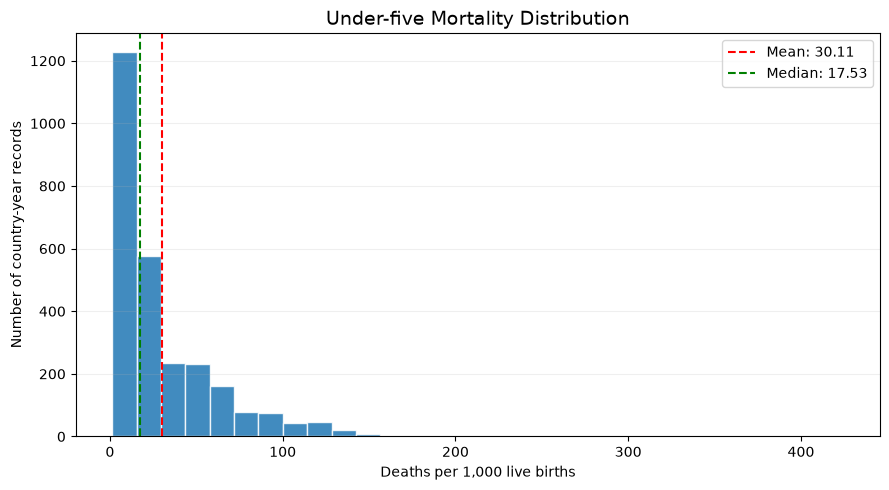

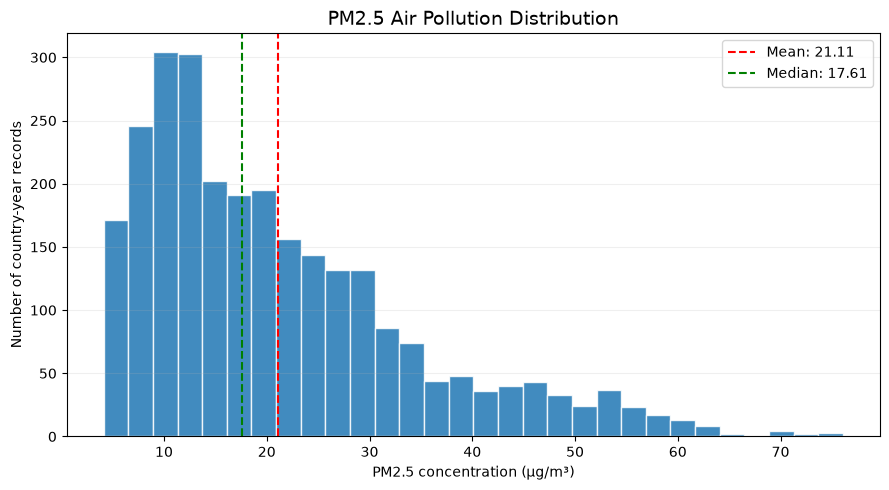

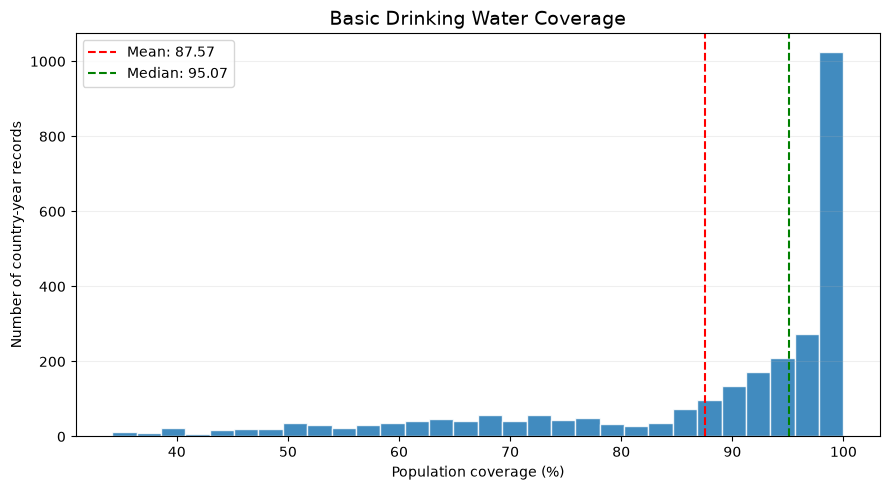

All 3 distribution charts saved successfully!


In [16]:

# STEP 20: Distribution visualizations

import matplotlib.pyplot as plt
from pathlib import Path

# Create folder for project figures
figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Variables, titles, and units
plots = {
    "Under5_Mortality_Rate": (
        "Under-five Mortality Distribution",
        "Deaths per 1,000 live births",
        "mortality_distribution.png"
    ),
    "PM25": (
        "PM2.5 Air Pollution Distribution",
        "PM2.5 concentration (µg/m³)",
        "pm25_distribution.png"
    ),
    "Water_AtLeastBasic_Pct": (
        "Basic Drinking Water Coverage",
        "Population coverage (%)",
        "water_distribution.png"
    )
}

for column, (title, xlabel, filename) in plots.items():

    values = eda_df[column].dropna()

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.hist(
        values,
        bins=30,
        edgecolor="white",
        alpha=0.85
    )

    ax.axvline(
        values.mean(),
        color="red",
        linestyle="--",
        label=f"Mean: {values.mean():.2f}"
    )

    ax.axvline(
        values.median(),
        color="green",
        linestyle="--",
        label=f"Median: {values.median():.2f}"
    )

    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of country-year records")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()

    fig.savefig(
        figures_dir / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("All 3 distribution charts saved successfully!")


=== OUTLIER ANALYSIS ===

Under-five Mortality
Lower bound: -47.94
Upper bound: 98.4
Outlier records: 136
Outlier percentage: 5.01 %


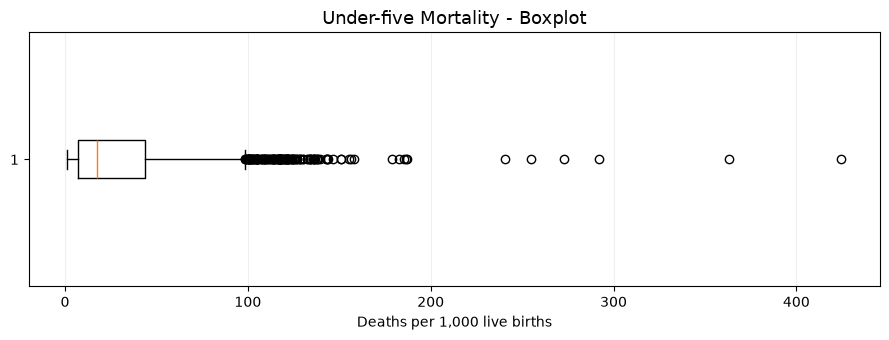


PM2.5 Air Pollution
Lower bound: -14.46
Upper bound: 53.33
Outlier records: 90
Outlier percentage: 3.32 %


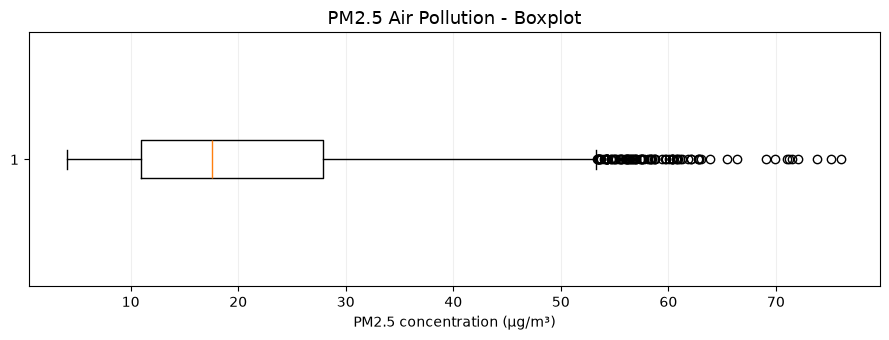


At Least Basic Drinking Water Coverage
Lower bound: 54.38
Upper bound: 125.97
Outlier records: 181
Outlier percentage: 6.67 %


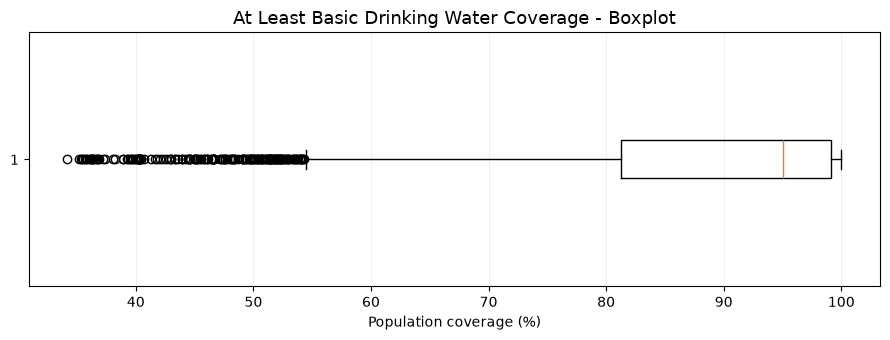


All 3 boxplots saved successfully!


In [17]:

# STEP 21: Boxplots and IQR Outlier Detection

import matplotlib.pyplot as plt
from pathlib import Path

figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Variables with clear titles and measurement units
variables = {
    "Under5_Mortality_Rate": (
        "Under-five Mortality",
        "Deaths per 1,000 live births"
    ),
    "PM25": (
        "PM2.5 Air Pollution",
        "PM2.5 concentration (µg/m³)"
    ),
    "Water_AtLeastBasic_Pct": (
        "At Least Basic Drinking Water Coverage",
        "Population coverage (%)"
    )
}

print("=== OUTLIER ANALYSIS ===")

for column, (title, xlabel) in variables.items():

    values = eda_df[column].dropna()

    # Calculate IQR
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = values[
        (values < lower) | (values > upper)
    ]

    print(f"\n{title}")
    print("Lower bound:", round(lower, 2))
    print("Upper bound:", round(upper, 2))
    print("Outlier records:", len(outliers))
    print(
        "Outlier percentage:",
        round(len(outliers) / len(values) * 100, 2),
        "%"
    )

    # Generate boxplot
    fig, ax = plt.subplots(figsize=(9, 3.5))

    ax.boxplot(
        values,
        orientation="horizontal",
        showfliers=True
    )

    ax.set_title(f"{title} - Boxplot", fontsize=13)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", alpha=0.2)

    plt.tight_layout()

    # Save figure
    filename = column + "_boxplot.png"

    fig.savefig(
        figures_dir / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("\nAll 3 boxplots saved successfully!")



## 4. Correlation Analysis

### 4.1 Pearson and Spearman Correlations

We calculated Pearson and Spearman correlations
to explore the relationships between environmental
factors and under-five mortality.

Pearson measures linear relationships, while
Spearman uses the ranking of observations.

| Factor | Pearson | Spearman |
|---|---:|---:|
| PM2.5 Air Pollution | +0.360 | +0.427 |
| Basic Drinking Water | -0.820 | -0.862 |

### 4.2 Main Findings

**Air Pollution**

PM2.5 shows a moderate positive association
with child mortality in the pooled dataset.

Countries and years with higher PM2.5 levels
tend to have higher mortality rates.

**Drinking Water**

Basic drinking water access has a strong
negative association with child mortality.

Higher water coverage is generally associated
with lower mortality rates.

These are statistical associations,
not evidence of direct causation.

### 4.3 Within-Country Analysis

The dataset contains repeated observations
of the same countries across several years.

To examine changes within countries, we
subtracted each country's average from its
observations and recalculated the correlations.

| Factor | Pooled Pearson | Within-Country Pearson |
|---|---:|---:|
| PM2.5 | +0.360 | +0.107 |
| Basic Drinking Water | -0.820 | -0.428 |

### 4.4 Interpretation

After removing country averages, the PM2.5
correlation becomes much weaker.

The negative relationship between drinking
water access and child mortality remains,
but its strength also decreases.

This suggests that differences between
countries contribute to the pooled results.

However, within-country correlations do not
control for all changing conditions or common
time trends.

For this reason, we also use regression models
with country and year fixed effects.


In [18]:

# STEP 22: Pearson and Spearman Correlation Analysis

import pandas as pd

variables = [
    "Under5_Mortality_Rate",
    "PM25",
    "Water_AtLeastBasic_Pct"
]

# Pearson correlation
pearson_corr = eda_df[variables].corr(
    method="pearson"
)

# Spearman correlation
spearman_corr = eda_df[variables].corr(
    method="spearman"
)

print("=== PEARSON CORRELATION ===")
display(pearson_corr.round(3))

print("\n=== SPEARMAN CORRELATION ===")
display(spearman_corr.round(3))

print("\n=== RELATIONSHIPS WITH CHILD MORTALITY ===")

comparison = pd.DataFrame({
    "Pearson": pearson_corr["Under5_Mortality_Rate"],
    "Spearman": spearman_corr["Under5_Mortality_Rate"]
})

display(comparison.round(3))


=== PEARSON CORRELATION ===


,Under5_Mortality_Rate,PM25,Water_AtLeastBasic_Pct
Under5_Mortality_Rate,1.00,0.360,-0.820
PM25,0.36,1.000,-0.284
Water_AtLeastBasic_Pct,-0.82,-0.284,1.000



=== SPEARMAN CORRELATION ===


,Under5_Mortality_Rate,PM25,Water_AtLeastBasic_Pct
Under5_Mortality_Rate,1.000,0.427,-0.862
PM25,0.427,1.000,-0.415
Water_AtLeastBasic_Pct,-0.862,-0.415,1.000



=== RELATIONSHIPS WITH CHILD MORTALITY ===


,Pearson,Spearman
Under5_Mortality_Rate,1.00,1.000
PM25,0.36,0.427
Water_AtLeastBasic_Pct,-0.82,-0.862


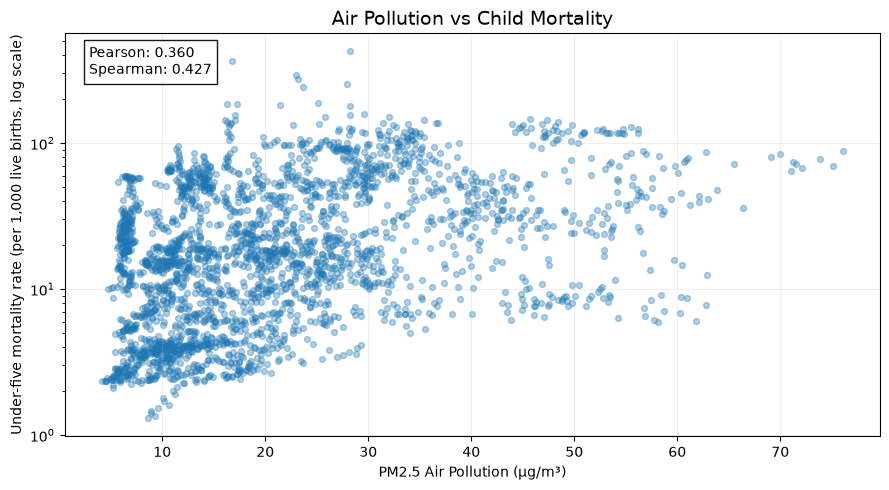

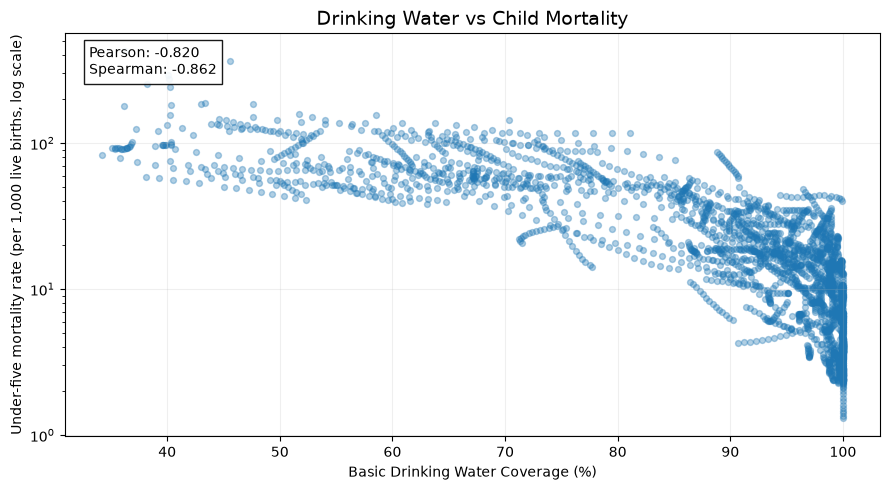

Both scatter plots saved successfully!


In [19]:

# STEP 23: Scatter Plots - Environmental Factors vs Child Mortality

import matplotlib.pyplot as plt
from pathlib import Path

figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plots = [
    (
        "PM25",
        "PM2.5 Air Pollution (µg/m³)",
        "Air Pollution vs Child Mortality",
        "pm25_vs_mortality.png"
    ),
    (
        "Water_AtLeastBasic_Pct",
        "Basic Drinking Water Coverage (%)",
        "Drinking Water vs Child Mortality",
        "water_vs_mortality.png"
    )
]

for column, xlabel, title, filename in plots:

    pearson = eda_df[column].corr(
        eda_df["Under5_Mortality_Rate"],
        method="pearson"
    )

    spearman = eda_df[column].corr(
        eda_df["Under5_Mortality_Rate"],
        method="spearman"
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.scatter(
        eda_df[column],
        eda_df["Under5_Mortality_Rate"],
        alpha=0.35,
        s=18
    )

    # Log scale helps display skewed mortality values
    ax.set_yscale("log")

    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(
        "Under-five mortality rate "
        "(per 1,000 live births, log scale)"
    )

    ax.text(
        0.03, 0.97,
        f"Pearson: {pearson:.3f}\n"
        f"Spearman: {spearman:.3f}",
        transform=ax.transAxes,
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.9
        )
    )

    ax.grid(alpha=0.2)

    plt.tight_layout()

    fig.savefig(
        figures_dir / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("Both scatter plots saved successfully!")



### 4.5 Scatter Plot Interpretation

We created two scatter plots to visualize the
relationships between environmental factors and
under-five mortality.

Each point represents one country-year observation.

**Logarithmic Display Scale**

The mortality axis uses a logarithmic scale because
the mortality data are strongly right-skewed.

This improves the visibility of observations with
lower mortality rates.

However, the Pearson and Spearman correlations
displayed on the plots were calculated using
the original, untransformed values.

The logarithmic axis changes only how the data
are displayed, not how the correlations were
calculated.

**Interpretation**

The PM2.5 plot shows a positive pooled association
with under-five mortality.

The drinking water plot shows a strong negative
pooled association with mortality.

These plots are descriptive. Countries contribute
multiple observations across years, and the points
are not statistically independent.

Therefore, the scatter plots and correlations
should not be interpreted as causal evidence.

Country and year fixed-effects models were used
later to examine these associations more carefully.


In [20]:

# STEP 24: Within-Country Correlation Analysis

import pandas as pd

variables = [
    "Under5_Mortality_Rate",
    "PM25",
    "Water_AtLeastBasic_Pct"
]

# Work on a copy of the main analysis dataset
within_df = eda_df.copy()

# Remove each country's average from its observations
for col in variables:
    within_df[col + "_within"] = (
        within_df[col]
        - within_df.groupby("ISO3")[col].transform("mean")
    )

# Correlations using the original pooled data
pooled_corr = eda_df[variables].corr(
    method="pearson"
)

# Correlations using within-country deviations
within_columns = [
    col + "_within" for col in variables
]

within_corr = within_df[within_columns].corr(
    method="pearson"
)

# Compare results
comparison = pd.DataFrame({
    "Factor": [
        "PM2.5 Air Pollution",
        "Basic Drinking Water"
    ],
    "Pooled_Pearson": [
        pooled_corr.loc["PM25", "Under5_Mortality_Rate"],
        pooled_corr.loc[
            "Water_AtLeastBasic_Pct",
            "Under5_Mortality_Rate"
        ]
    ],
    "Within_Country_Pearson": [
        within_corr.loc[
            "PM25_within",
            "Under5_Mortality_Rate_within"
        ],
        within_corr.loc[
            "Water_AtLeastBasic_Pct_within",
            "Under5_Mortality_Rate_within"
        ]
    ]
})

print("=== WITHIN-COUNTRY ANALYSIS ===")
print("Records:", len(within_df))
print("Countries:", within_df["ISO3"].nunique())

display(comparison.round(3))

print("\n=== COUNTRY COVERAGE ===")
display(
    within_df.groupby("ISO3")["Year"]
    .nunique()
    .describe()
)


=== WITHIN-COUNTRY ANALYSIS ===
Records: 2713
Countries: 198


,Factor,Pooled_Pearson,Within_Country_Pearson
0,PM2.5 Air Pollution,0.36,0.107
1,Basic Drinking Water,-0.82,-0.428



=== COUNTRY COVERAGE ===


count    198.000000
mean      13.702020
std        1.265351
min        7.000000
25%       14.000000
50%       14.000000
75%       14.000000
max       14.000000
Name: Year, dtype: float64


## 5. Statistical Modelling and Robustness Checks

### 5.1 Analysis Strategy

We used regression models to examine the relationships
between under-five mortality, air pollution, and
drinking water access.

**Outcome variable:**
- Under-five mortality rate per 1,000 live births.

**Explanatory variables:**
- PM2.5 concentration (µg/m³).
- Drinking water coverage (%).

We used five complementary analyses:

1. **Two-Way Fixed Effects:** Estimates associations
   while controlling for country and year differences.

2. **Log-Linear Fixed Effects:** Examines relative
   differences in mortality using a log transformation.

3. **Sensitivity Analysis:** Checks whether extreme
   mortality observations strongly affect the results.

4. **Water Indicator Comparison:** Compares basic and
   safely managed water access on the same sample.

5. **First-Difference Regression:** Examines annual
   changes within countries, with year fixed effects.

Regression standard errors are clustered by country.

Each model is presented with its code, results, and
interpretation.

### Important Considerations

These models estimate statistical associations,
not causal effects.

Differences across model specifications are examined
rather than ignored.

Potential omitted factors include income, healthcare
quality, education, and conflict.


In [21]:

# STEP 25: Two-Way Fixed Effects Regression

import pandas as pd
import statsmodels.formula.api as smf

# Prepare the regression dataset
model_df = eda_df[
    [
        "ISO3",
        "Year",
        "Under5_Mortality_Rate",
        "PM25",
        "Water_AtLeastBasic_Pct"
    ]
].dropna().copy()

# Country and Year Fixed Effects
formula = (
    "Under5_Mortality_Rate ~ "
    "PM25 + Water_AtLeastBasic_Pct "
    "+ C(ISO3) + C(Year)"
)

# Fit model with country-clustered standard errors
fe_model = smf.ols(
    formula=formula,
    data=model_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": model_df["ISO3"]
    }
)

# Extract the main regression results
factors = [
    "PM25",
    "Water_AtLeastBasic_Pct"
]

confidence_intervals = fe_model.conf_int()

results = pd.DataFrame({
    "Coefficient": fe_model.params[factors],
    "Std_Error": fe_model.bse[factors],
    "P_Value": fe_model.pvalues[factors],
    "CI_Lower": confidence_intervals.loc[factors, 0],
    "CI_Upper": confidence_intervals.loc[factors, 1]
})

print("=== TWO-WAY FIXED EFFECTS RESULTS ===")

print("Observations:", int(fe_model.nobs))
print("Countries:", model_df["ISO3"].nunique())
print("Years:", model_df["Year"].nunique())
print("R-squared:", round(fe_model.rsquared, 4))

display(results.round(4))


=== TWO-WAY FIXED EFFECTS RESULTS ===
Observations: 2713
Countries: 198
Years: 14
R-squared: 0.9245


,Coefficient,Std_Error,P_Value,CI_Lower,CI_Upper
PM25,-0.1483,0.1329,0.2644,-0.4087,0.1121
Water_AtLeastBasic_Pct,-1.4709,0.3078,0.0000,-2.0742,-0.8675



### 5.2 Two-Way Fixed Effects — Results and Interpretation

This model estimates associations with under-five
mortality measured in deaths per 1,000 live births.

It includes country and year fixed effects, with
standard errors clustered by country.

**Air pollution (PM2.5)**

The estimated coefficient was -0.1483 (p = 0.2644).

The 95% confidence interval was [-0.4087, 0.1121].

Since the p-value is above 0.05 and the confidence
interval includes zero, the association was not
statistically significant in this specification.

**Basic drinking water**

The estimated coefficient was -1.4709 (p < 0.0001).

A one-percentage-point increase in basic drinking
water coverage was associated with approximately
1.47 fewer under-five deaths per 1,000 live births,
holding the model's fixed effects and PM2.5 constant.

This association was statistically significant.

**Model interpretation**

The model R-squared was 0.9245. This includes
variation explained by country and year fixed effects,
not only the two environmental variables.

The results are observational and cannot establish
causation.

The difference between this model and the log-linear
model will be discussed in the final model comparison.


In [22]:

# STEP 26: Log-Linear Fixed Effects Regression

import numpy as np

# Keep observations with positive mortality rates
log_df = model_df[
    model_df["Under5_Mortality_Rate"] > 0
].copy()

# Natural logarithm of child mortality
log_df["Log_Mortality"] = np.log(
    log_df["Under5_Mortality_Rate"]
)

# Country and year fixed-effects model
log_formula = (
    "Log_Mortality ~ "
    "PM25 + Water_AtLeastBasic_Pct "
    "+ C(ISO3) + C(Year)"
)

log_model = smf.ols(
    formula=log_formula,
    data=log_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": log_df["ISO3"]}
)

# Extract main results
log_factors = ["PM25", "Water_AtLeastBasic_Pct"]

log_results = pd.DataFrame({
    "Coefficient": log_model.params[log_factors],
    "Std_Error": log_model.bse[log_factors],
    "P_Value": log_model.pvalues[log_factors]
})

# Convert log coefficients into percentage changes
log_results["Percent_Change"] = (
    np.exp(log_results["Coefficient"]) - 1
) * 100

print("=== LOG-LINEAR FIXED EFFECTS ===")
print("Observations:", int(log_model.nobs))
print("Countries:", log_df["ISO3"].nunique())
print("R-squared:", round(log_model.rsquared, 4))

display(log_results.round(4))


=== LOG-LINEAR FIXED EFFECTS ===
Observations: 2713
Countries: 198
R-squared: 0.9914


,Coefficient,Std_Error,P_Value,Percent_Change
PM25,0.0071,0.0023,0.0021,0.7087
Water_AtLeastBasic_Pct,-0.0110,0.0025,0.0000,-1.0933



### 5.3 Log-Linear Fixed Effects — Results and Interpretation

We used the natural logarithm of under-five mortality
to examine relative differences in mortality rates.

The model includes country and year fixed effects,
with standard errors clustered by country.

**Model results**

| Variable | Coefficient | P-value | Estimated Change |
|---|---:|---:|---:|
| PM2.5 | 0.0071 | 0.0021 | +0.7087% |
| Basic Water | -0.0110 | <0.0001 | -1.0933% |

- Observations: 2,713
- Countries: 198
- R-squared: 0.9914

**Interpretation**

A 1 µg/m³ increase in PM2.5 was associated with
approximately 0.71% higher under-five mortality,
holding the other model terms constant.

A one-percentage-point increase in basic drinking
water coverage was associated with approximately
1.09% lower under-five mortality.

Both associations were statistically significant.

**Comparison with the level model**

Unlike the level fixed-effects model, PM2.5 showed
a positive and statistically significant association
in this log-linear specification.

This difference indicates sensitivity to the
functional form of the regression model.

The high R-squared includes the contribution of
country and year fixed effects.

The estimates represent statistical associations,
not causal effects.


In [23]:

# STEP 27: Sensitivity Analysis - Extreme Mortality Values

# Exclude observations with mortality above 200
sensitivity_df = log_df[
    log_df["Under5_Mortality_Rate"] <= 200
].copy()

# Fit the same log-linear fixed effects model
sensitivity_model = smf.ols(
    formula=log_formula,
    data=sensitivity_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": sensitivity_df["ISO3"]}
)

# Compare original and sensitivity results
comparison = pd.DataFrame({
    "Original_Coefficient": log_model.params[log_factors],
    "Sensitivity_Coefficient": sensitivity_model.params[log_factors],
    "Original_P_Value": log_model.pvalues[log_factors],
    "Sensitivity_P_Value": sensitivity_model.pvalues[log_factors]
})

comparison["Original_Percent"] = (
    np.exp(comparison["Original_Coefficient"]) - 1
) * 100

comparison["Sensitivity_Percent"] = (
    np.exp(comparison["Sensitivity_Coefficient"]) - 1
) * 100

print("=== SENSITIVITY ANALYSIS ===")

print("Original observations:", len(log_df))
print("Sensitivity observations:", len(sensitivity_df))
print("Excluded observations:", len(log_df) - len(sensitivity_df))

print("Sensitivity R-squared:",
      round(sensitivity_model.rsquared, 4))

display(comparison.round(4))


=== SENSITIVITY ANALYSIS ===
Original observations: 2713
Sensitivity observations: 2707
Excluded observations: 6
Sensitivity R-squared: 0.9925


,Original_Coefficient,Sensitivity_Coefficient,Original_P_Value,Sensitivity_P_Value,Original_Percent,Sensitivity_Percent
PM25,0.0071,0.0068,0.0021,0.0024,0.7087,0.6825
Water_AtLeastBasic_Pct,-0.0110,-0.0096,0.0000,0.0000,-1.0933,-0.9575



### 5.4 Sensitivity Analysis — Results and Interpretation

**Purpose**

We tested whether very high mortality observations
strongly influenced the log-linear regression results.

For this sensitivity test, we excluded observations
with under-five mortality rates above 200 per
1,000 live births.

This threshold was used as an exploratory sensitivity
cutoff, not as evidence that these values were incorrect.

**Sample Comparison**

| Measure | Original Model | Sensitivity Model |
|---|---:|---:|
| Observations | 2,713 | 2,707 |
| Excluded observations | 0 | 6 |
| R-squared | 0.9914 | 0.9925 |

**Regression Results**

| Variable | Original Estimate | Sensitivity Estimate |
|---|---:|---:|
| PM2.5 | +0.7087% | +0.6825% |
| Basic Water | -1.0933% | -0.9575% |

After excluding six observations:

- PM2.5 remained positively associated with mortality
  (p = 0.0024).
- Basic drinking water remained negatively associated
  with mortality (p < 0.0001).
- Both associations remained statistically significant.
- The estimated percentage changes were relatively
  close to those from the original model.

**Interpretation**

The findings were reasonably stable under this
specific sensitivity test.

The changes in the coefficients were limited,
although the water estimate became somewhat smaller
in magnitude.

This result does not prove that the model is free
from bias or that the associations are causal.

All excluded observations remain in the original
and main analysis datasets. They were removed only
for this separate sensitivity regression.


In [24]:

# STEP 28: Basic vs Safely Managed Water Comparison

# Load observations with safely managed water data
water_comparison_df = pd.read_csv(
    "data/processed/secondary_analysis.csv"
)

required_columns = [
    "ISO3",
    "Year",
    "Under5_Mortality_Rate",
    "PM25",
    "Water_AtLeastBasic_Pct",
    "Water_SafelyManaged_Pct"
]

water_comparison_df = (
    water_comparison_df[required_columns]
    .dropna()
    .copy()
)

water_comparison_df = water_comparison_df[
    water_comparison_df["Under5_Mortality_Rate"] > 0
].copy()

water_comparison_df["Log_Mortality"] = np.log(
    water_comparison_df["Under5_Mortality_Rate"]
)

# Fit both models on exactly the same observations
water_models = {}

for water_variable in [
    "Water_AtLeastBasic_Pct",
    "Water_SafelyManaged_Pct"
]:
    model_formula = (
        f"Log_Mortality ~ PM25 + {water_variable} "
        "+ C(ISO3) + C(Year)"
    )

    fitted_model = smf.ols(
        formula=model_formula,
        data=water_comparison_df
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": water_comparison_df["ISO3"]
        }
    )

    water_models[water_variable] = fitted_model

# Build comparison table
water_results = []

for water_variable, fitted_model in water_models.items():
    for factor in ["PM25", water_variable]:
        coefficient = fitted_model.params[factor]

        water_results.append({
            "Water_Model": water_variable,
            "Factor": factor,
            "Coefficient": coefficient,
            "P_Value": fitted_model.pvalues[factor],
            "Percent_Change": (
                np.exp(coefficient) - 1
            ) * 100
        })

water_results = pd.DataFrame(water_results)

print("=== WATER INDICATOR COMPARISON ===")
print("Observations:", len(water_comparison_df))
print("Countries:", water_comparison_df["ISO3"].nunique())
print("Years:", water_comparison_df["Year"].nunique())

display(water_results.round(4))


=== WATER INDICATOR COMPARISON ===
Observations: 1932
Countries: 139
Years: 14


,Water_Model,Factor,Coefficient,P_Value,Percent_Change
0,Water_AtLeastBasic_Pct,PM25,0.0070,0.0050,0.7064
1,Water_AtLeastBasic_Pct,Water_AtLeastBasic_Pct,-0.0102,0.0018,-1.0147
2,Water_SafelyManaged_Pct,PM25,0.0067,0.0040,0.6703
3,Water_SafelyManaged_Pct,Water_SafelyManaged_Pct,-0.0075,0.0030,-0.7510



### 5.5 Water Indicator Comparison — Results and Interpretation

**Purpose**

We examined whether the relationship between drinking
water access and under-five mortality remained similar
when using a different water service indicator.

We compared two indicators:

- **At least basic water:** Access to at least basic
  drinking water services.
- **Safely managed water:** Access to drinking water
  services that meet stricter safety and availability
  requirements.

**Method**

We estimated two separate log-linear regression models.

Both models used exactly the same country-year observations,
with country and year fixed effects and standard errors
clustered by country.

The models included PM2.5 and one water indicator at a time.

**Sample**

- Observations: 1,932
- Countries and territories: 139
- Period: 2010–2023
- Years represented: 14

**Regression Results**

| Variable | Basic Water Model | Safely Managed Model |
|---|---:|---:|
| PM2.5 coefficient | 0.0070 | 0.0067 |
| PM2.5 p-value | 0.0050 | 0.0040 |
| Water coefficient | -0.0102 | -0.0075 |
| Water p-value | 0.0018 | 0.0030 |
| Estimated water change | -1.0147% | -0.7510% |

**Interpretation**

In the basic water model, a one-percentage-point
increase in water coverage was associated with
approximately 1.01% lower under-five mortality.

In the safely managed water model, the corresponding
association was approximately 0.75% lower mortality.

Both water coefficients were negative and statistically
significant.

PM2.5 also showed positive, statistically significant
associations in both models.

**Important Considerations**

Using the same observations makes the comparison
less sensitive to differences in sample composition.

However, the two water indicators represent different
service definitions.

Their coefficient magnitudes should not be interpreted
as proof that one water service has a stronger causal
effect than the other.

The findings support a negative statistical association
between drinking water access and under-five mortality,
but they do not establish causation.


In [25]:

# STEP 29: First-Difference Regression with Year Fixed Effects

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from IPython.display import display

# 1. Prepare the dataset
fd_df = log_df.sort_values(
    ["ISO3", "Year"]
).copy()

# 2. Calculate the gap between consecutive years
fd_df["Year_Gap"] = (
    fd_df.groupby("ISO3")["Year"].diff()
)

# 3. Calculate annual changes within each country
fd_df["Delta_Log_Mortality"] = (
    fd_df.groupby("ISO3")["Log_Mortality"].diff()
)

fd_df["Delta_PM25"] = (
    fd_df.groupby("ISO3")["PM25"].diff()
)

fd_df["Delta_Water"] = (
    fd_df.groupby("ISO3")[
        "Water_AtLeastBasic_Pct"
    ].diff()
)

# 4. Keep only consecutive-year observations
fd_df = fd_df[
    fd_df["Year_Gap"] == 1
].dropna(
    subset=[
        "Delta_Log_Mortality",
        "Delta_PM25",
        "Delta_Water"
    ]
).copy()

# 5. First-difference regression with year fixed effects
fd_formula = (
    "Delta_Log_Mortality ~ "
    "Delta_PM25 + Delta_Water + C(Year)"
)

fd_model = smf.ols(
    formula=fd_formula,
    data=fd_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": fd_df["ISO3"]}
)

# 6. Extract model results
fd_factors = ["Delta_PM25", "Delta_Water"]

fd_results = pd.DataFrame({
    "Coefficient": fd_model.params[fd_factors],
    "Std_Error": fd_model.bse[fd_factors],
    "P_Value": fd_model.pvalues[fd_factors]
})

# Convert log coefficients to percentage changes
fd_results["Percent_Change"] = (
    np.exp(fd_results["Coefficient"]) - 1
) * 100

# 7. Display results
print("=== FIRST-DIFFERENCE REGRESSION ===")
print("Model: First Differences + Year Fixed Effects")
print("Observations:", int(fd_model.nobs))
print("Countries:", fd_df["ISO3"].nunique())
print("R-squared:", round(fd_model.rsquared, 4))

display(fd_results.round(4))


=== FIRST-DIFFERENCE REGRESSION ===
Model: First Differences + Year Fixed Effects
Observations: 2515
Countries: 198
R-squared: 0.0163


,Coefficient,Std_Error,P_Value,Percent_Change
Delta_PM25,0.0017,0.0006,0.0059,0.1683
Delta_Water,-0.0109,0.0022,0.0000,-1.0806



### 5.6 First-Difference Regression — Results and Interpretation

**Purpose**

We used first differences to examine whether annual
changes in air pollution and drinking water access
were associated with annual changes in under-five
mortality within countries.

Unlike the previous models, this approach focuses
on changes between consecutive years rather than
the original levels of the variables.

**Method**

For each country, we calculated:

- Annual change in log under-five mortality.
- Annual change in PM2.5 concentration.
- Annual change in basic drinking water coverage.

Only consecutive-year observations were included.

The regression also included year fixed effects
to account for common changes across countries.

Standard errors were clustered by country.

**Sample**

- Observations: 2,515
- Countries and territories: 198
- Period: 2010–2023

**Regression Results**

| Variable | Coefficient | P-value | Estimated Change |
|---|---:|---:|---:|
| Change in PM2.5 | 0.0017 | 0.0059 | +0.1683% |
| Change in Basic Water | -0.0109 | <0.0001 | -1.0806% |

Model R-squared: 0.0163.

**Interpretation**

A 1 µg/m³ greater annual increase in PM2.5 was
associated with approximately 0.17% higher annual
mortality growth, holding the other model terms
constant.

A one-percentage-point greater annual increase
in basic water coverage was associated with
approximately 1.08% lower annual mortality growth.

Both coefficients were statistically significant.

**Model Limitations**

The R-squared of 0.0163 indicates that the model
explained approximately 1.63% of the observed
variation in annual log-mortality changes.

Most annual variation remained unexplained.

First differencing removes country characteristics
that are constant over time, but it does not eliminate
all possible confounding factors.

Time-varying factors, measurement error, and omitted
variables may still affect the estimates.

**Conclusion**

The directions of both associations were consistent
with those in the log-linear fixed-effects model.

However, the limited explanatory power and
observational nature of the data require
cautious interpretation.

The findings do not establish causation.



### 5.7 Model Comparison and Limitations

#### Comparison of Main Models

We compared the regression results to assess
whether the observed associations were consistent
across different model specifications.

| Model | Observations | PM2.5 Result | Basic Water Result |
|---|---:|---|---|
| Level Fixed Effects | 2,713 | Negative, not significant (p = 0.2644) | Negative, significant (p < 0.0001) |
| Log-Linear Fixed Effects | 2,713 | Positive, significant (p = 0.0021) | Negative, significant (p < 0.0001) |
| Log Sensitivity Analysis | 2,707 | Positive, significant (p = 0.0024) | Negative, significant (p < 0.0001) |
| First Differences + Year Effects | 2,515 | Positive, significant (p = 0.0059) | Negative, significant (p < 0.0001) |

The water indicator comparison was conducted
separately on the same 1,932 observations.
Both basic and safely managed water indicators
showed negative, statistically significant
associations with mortality.

#### Main Findings

**1. Drinking Water**

Basic drinking water access showed a consistent
negative association with under-five mortality
across the main regression specifications.

The direction and statistical significance of
this relationship were relatively stable.

**2. Air Pollution**

The PM2.5 results were more sensitive to the
model specification.

The level fixed-effects model produced a negative,
non-significant coefficient.

In contrast, the log-linear and first-difference
models produced positive, statistically significant
coefficients.

This difference means that the PM2.5 relationship
should be interpreted cautiously.

**3. Sensitivity to Extreme Values**

Removing six observations with mortality rates
above 200 did not substantially change the
log-linear estimates.

However, this single sensitivity test cannot
rule out other sources of model uncertainty.

#### Interpreting Model Differences

The models estimate relationships on different
outcome scales:

- The level model uses mortality rates directly.
- The log model uses log mortality rates.
- The first-difference model uses annual changes
  in log mortality.

Consequently, their coefficients and R-squared
values are not directly comparable.

The high R-squared values in the fixed-effects
models also reflect the contribution of country
and year effects.

The first-difference model had an R-squared
of 0.0163, indicating limited explanatory power
for annual log-mortality changes.

#### Methodological Limitations

Several limitations remain:

- Observational data cannot establish causation.
- Income, healthcare quality, education, and
  conflict were not included as control variables.
- Time-varying confounding may remain.
- Measurement errors may affect the estimates.
- Missing water data reduce the available sample.
- Results may depend on model specification.
- Country-level associations cannot be directly
  interpreted as individual-level relationships.

#### Overall Assessment

The most consistent finding was the negative
association between drinking water access and
under-five mortality.

The evidence concerning PM2.5 was less consistent
because its sign and statistical significance
differed across specifications.

These findings are useful for exploratory
cross-country analysis, but further research
with additional explanatory variables and
validation would be needed before drawing
stronger conclusions.



## 6. Final Findings and Conclusion

### 6.1 Research Summary

This project investigated the relationships between
under-five mortality, PM2.5 air pollution, and
drinking water access across countries during 2010–2023.

We integrated data from UNICEF, WHO, and the
WHO/UNICEF Joint Monitoring Programme (JMP).

The main analysis included 2,713 country-year
observations from 198 countries and territories.

### 6.2 Main Conclusions

The analysis produced three main findings:

**Drinking Water**

Higher access to basic drinking water was consistently
associated with lower under-five mortality across
the main regression specifications.

**Air Pollution**

The association between PM2.5 and child mortality
depended on the statistical model.

The log-linear and first-difference models showed
positive, statistically significant associations.
However, the level fixed-effects model did not
show a statistically significant association.

**Robustness**

The log-linear estimates remained relatively stable
after excluding six unusually high mortality
observations.

These results describe statistical associations,
not causal effects.

### 6.3 Project Contributions

The project produced:

- An integrated country-year dataset from three
  international data sources.
- A reproducible Python data preparation pipeline.
- Automated data quality checks.
- Exploratory analysis and statistical models.
- Sensitivity analyses and model comparisons.
- An interactive Streamlit dashboard for exploring
  country trends and downloading selected data.

### 6.4 Future Research

Future work could incorporate additional variables,
including income, healthcare access, education,
and conflict indicators.

Further validation of unusual mortality estimates,
alternative model specifications, and data quality
would also strengthen the analysis.

### 6.5 Final Statement

This project demonstrates how international health
and environmental data can be combined and analysed
using Python.

The most consistent statistical finding concerns
the negative association between drinking water
access and under-five mortality.

The mixed PM2.5 results highlight the importance
of comparing models and interpreting observational
data carefully.
